# 24. Molecular Featurization I: SMILES and RDKit
@Shengli (Bruce) Jiang, University of South Carolina

## What We Covered in the Last Lecture

- Permutation importance measures how shuffling a feature changes prediction error.
- PDP and ICE show how predictions change as one feature varies.
- SHAP assigns feature contributions relative to a reference prediction.


## Today's Learning Objectives

- Read a SMILES string and draw the molecule with RDKit.
- Inspect atoms and bonds, including hydrogens, charges, and stereochemistry.
- Build one-hot encodings and atom-count and bond-count vectors.
- Explain why different molecules can have the same count vector.


## Setup

Run the cells in order. All molecules are defined below.

If needed, run `%pip install rdkit numpy pandas matplotlib pillow` once, then restart the kernel.


In [1]:
%matplotlib inline

from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors

SEED = 26
BLUE, RED = '#4C91BC', '#E68178'
plt.rcParams.update({
    'font.size': 11, 'text.color': 'black', 'axes.titlecolor': 'black',
    'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black',
    'axes.spines.top': False, 'axes.spines.right': False,
})
print('RDKit version:', rdBase.rdkitVersion)

RDKit version: 2026.03.5


## Reading and Drawing Molecules

`Chem.MolFromSmiles()` converts a SMILES string into a molecular graph. It returns `None` if parsing fails.

SMILES describes connectivity and can include stereochemistry. It does not contain 3D coordinates.


In [2]:
ethanol = Chem.MolFromSmiles('CCO')
ether = Chem.MolFromSmiles('COC')
if ethanol is None or ether is None:
    raise ValueError('A teaching example could not be parsed.')

pair = {'Ethanol': ethanol, 'Dimethyl ether': ether}
display(pd.DataFrame({
    'SMILES': ['CCO', 'COC'],
    'Formula': [rdMolDescriptors.CalcMolFormula(m) for m in pair.values()],
    'Atoms in graph': [m.GetNumAtoms() for m in pair.values()],
    'Bonds in graph': [m.GetNumBonds() for m in pair.values()],
}, index=pair))

,SMILES,Formula,Atoms in graph,Bonds in graph
Ethanol,CCO,C2H6O,3,2
Dimethyl ether,COC,C2H6O,3,2


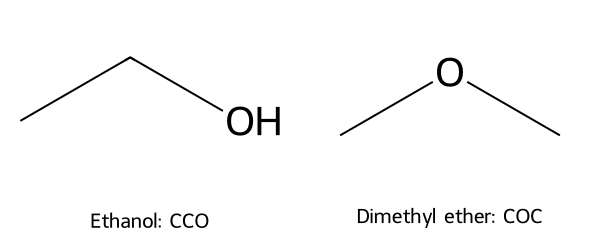

In [3]:
def draw_molecules(molecules, labels, columns=3, atom_indices=False):
    options = Draw.MolDrawOptions()
    options.useBWAtomPalette()
    options.legendFontSize = 20
    options.legendFraction = 0.22
    options.addAtomIndices = atom_indices
    grid = Draw.MolsToGridImage(
        [Chem.Mol(m) for m in molecules], legends=list(labels),
        molsPerRow=columns, subImgSize=(300, 240),
        drawOptions=options, useSVG=False,
    )
    display(grid)

draw_molecules(pair.values(), ['Ethanol: CCO', 'Dimethyl ether: COC'], columns=2)

### Invalid SMILES

RDKit returns `None` for the invalid strings below. The `rdBase.BlockLogs()` context suppresses the error messages for these examples.


In [4]:
invalid_examples = {
    'C1CC': 'Unclosed ring',
    'CO(C)C': 'Neutral oxygen with three single bonds',
    'c1cccc1': 'Aromatic assignment cannot be kekulized',
}
parse_checks = []
for smiles, issue in invalid_examples.items():
    with rdBase.BlockLogs():
        candidate = Chem.MolFromSmiles(smiles)
    parse_checks.append({'SMILES': smiles, 'Issue': issue,
                         'Returned None': candidate is None})
display(pd.DataFrame(parse_checks))

,SMILES,Issue,Returned None
0,C1CC,Unclosed ring,True
1,CO(C)C,Neutral oxygen with three single bonds,True
2,c1cccc1,Aromatic assignment cannot be kekulized,True


## Atoms, Bonds, and Hydrogens

RDKit numbers atoms from zero. `GetDegree()` counts neighboring atoms present in the graph. Implicit hydrogens do not contribute to this degree.

The tables below list ethanol's atoms and bonds.


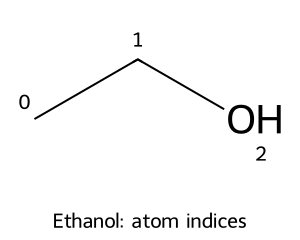

,Element,Degree,Attached H,Formal charge,Aromatic,In ring
Index,,,,,,
0,C,1,3,0,False,False
1,C,2,2,0,False,False
2,O,1,1,0,False,False


In [5]:
def atom_table(mol):
    return pd.DataFrame([{
        'Index': atom.GetIdx(), 'Element': atom.GetSymbol(),
        'Degree': atom.GetDegree(),
        'Attached H': atom.GetTotalNumHs(includeNeighbors=True),
        'Formal charge': atom.GetFormalCharge(),
        'Aromatic': atom.GetIsAromatic(), 'In ring': atom.IsInRing(),
    } for atom in mol.GetAtoms()]).set_index('Index')

draw_molecules([ethanol], ['Ethanol: atom indices'], columns=1, atom_indices=True)
display(atom_table(ethanol))

In [6]:
def bond_table(mol):
    return pd.DataFrame([{
        'Index': bond.GetIdx(),
        'Atom i': bond.GetBeginAtomIdx(), 'Atom j': bond.GetEndAtomIdx(),
        'Element i': bond.GetBeginAtom().GetSymbol(),
        'Element j': bond.GetEndAtom().GetSymbol(),
        'Bond type': str(bond.GetBondType()),
        'Aromatic': bond.GetIsAromatic(), 'In ring': bond.IsInRing(),
    } for bond in mol.GetBonds()]).set_index('Index')

display(bond_table(ethanol))

,Atom i,Atom j,Element i,Element j,Bond type,Aromatic,In ring
Index,,,,,,,
0,0,1,C,C,SINGLE,False,False
1,1,2,C,O,SINGLE,False,False


### Explicit Hydrogens

Ethanol has formula C₂H₆O. Its usual RDKit graph contains three atoms because the hydrogens are implicit. `Chem.AddHs()` returns a new graph with all nine atoms.

The `Attached H` column counts hydrogens whether implicit or present as neighboring atoms.


,Atoms,Bonds,Formula
Graph,,,
Implicit H,3,2,C2H6O
Explicit H,9,8,C2H6O


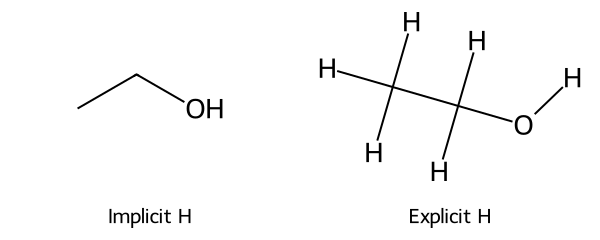

In [7]:
ethanol_with_h = Chem.AddHs(ethanol)
display(pd.DataFrame({
    'Graph': ['Implicit H', 'Explicit H'],
    'Atoms': [ethanol.GetNumAtoms(), ethanol_with_h.GetNumAtoms()],
    'Bonds': [ethanol.GetNumBonds(), ethanol_with_h.GetNumBonds()],
    'Formula': [rdMolDescriptors.CalcMolFormula(m)
                for m in [ethanol, ethanol_with_h]],
}).set_index('Graph'))
draw_molecules([ethanol, ethanol_with_h], ['Implicit H', 'Explicit H'], columns=2)

## Branches, Rings, and Aromaticity

- Parentheses attach a branch to the preceding atom.
- Matching ring labels connect two atoms. The label does not give the ring size.
- Lowercase symbols such as `c` and `o` indicate aromatic atoms.

RDKit checks the structure during parsing and assigns aromaticity. Compare benzene and cyclobutadiene in the table.


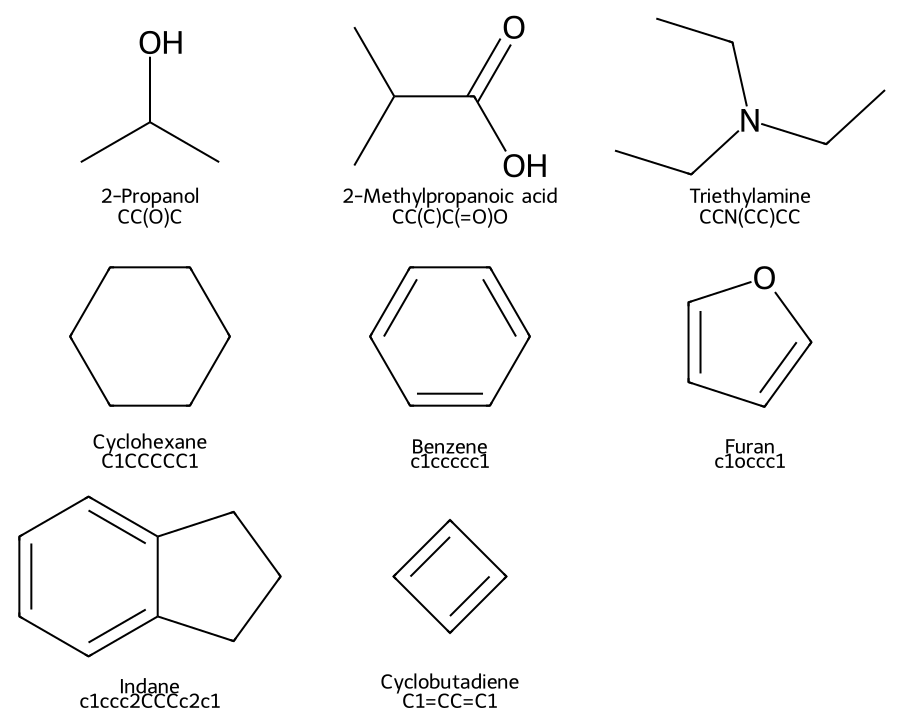

In [8]:
structure_smiles = {
    '2-Propanol': 'CC(O)C',
    '2-Methylpropanoic acid': 'CC(C)C(=O)O',
    'Triethylamine': 'CCN(CC)CC',
    'Cyclohexane': 'C1CCCCC1',
    'Benzene': 'c1ccccc1',
    'Furan': 'c1occc1',
    'Indane': 'c1ccc2CCCc2c1',
    'Cyclobutadiene': 'C1=CC=C1',
}
structures = {name: Chem.MolFromSmiles(s) for name, s in structure_smiles.items()}
if any(m is None for m in structures.values()):
    raise ValueError('A structure example could not be parsed.')
draw_molecules(structures.values(),
               [f'{name}\n{structure_smiles[name]}' for name in structures], columns=3)

In [9]:
display(pd.DataFrame([{
    'Molecule': name, 'Formula': rdMolDescriptors.CalcMolFormula(m),
    'Rings (RDKit)': m.GetRingInfo().NumRings(),
    'Aromatic atoms': sum(a.GetIsAromatic() for a in m.GetAtoms()),
    'Aromatic bonds': sum(b.GetIsAromatic() for b in m.GetBonds()),
} for name, m in structures.items()]).set_index('Molecule'))

aromatic_request = Chem.MolFromSmiles('c1ccc1')
print('Input c1ccc1 becomes:', Chem.MolToSmiles(aromatic_request))
print('Aromatic atoms after sanitization:',
      sum(a.GetIsAromatic() for a in aromatic_request.GetAtoms()))

,Formula,Rings (RDKit),Aromatic atoms,Aromatic bonds
Molecule,,,,
2-Propanol,C3H8O,0,0,0
2-Methylpropanoic acid,C4H8O2,0,0,0
Triethylamine,C6H15N,0,0,0
Cyclohexane,C6H12,1,0,0
Benzene,C6H6,1,6,6
Furan,C4H4O,1,5,5
Indane,C9H10,2,6,6
Cyclobutadiene,C4H4,1,0,0


Input c1ccc1 becomes: C1=CC=C1
Aromatic atoms after sanitization: 0


## Canonical SMILES

`CCO`, `OCC`, and `C(O)C` all describe ethanol. `Chem.MolToSmiles()` returns canonical SMILES by default, so these inputs give the same output.

Canonical strings can differ between toolkits or versions. Canonicalization also leaves different protonation states and tautomers distinct.


In [10]:
alternative_smiles = ['CCO', 'OCC', 'C(O)C']
equivalents = [Chem.MolFromSmiles(s) for s in alternative_smiles]
canonical = [Chem.MolToSmiles(m) for m in equivalents]
display(pd.DataFrame({'Input SMILES': alternative_smiles,
                      'RDKit canonical SMILES': canonical}))
print('Distinct input strings:', len(set(alternative_smiles)))
print('Distinct canonical strings:', len(set(canonical)))

,Input SMILES,RDKit canonical SMILES
0,CCO,CCO
1,OCC,CCO
2,C(O)C,CCO


Distinct input strings: 3
Distinct canonical strings: 1


## Charges

Brackets specify charge and hydrogen count, as in `[NH4+]`. A dot separates disconnected components, as in `[Na+].[Cl-]`.


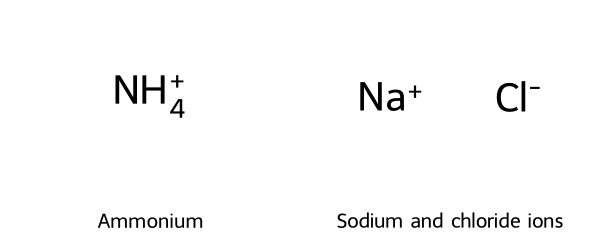

,Element,Degree,Attached H,Formal charge,Aromatic,In ring
Index,,,,,,
0,N,0,4,1,False,False


,Element,Degree,Attached H,Formal charge,Aromatic,In ring
Index,,,,,,
0,Na,0,0,1,False,False
1,Cl,0,0,-1,False,False


Salt fragments: 2
Total formal charge: 0


In [11]:
ammonium = Chem.MolFromSmiles('[NH4+]')
salt = Chem.MolFromSmiles('[Na+].[Cl-]')
draw_molecules([ammonium, salt], ['Ammonium', 'Sodium and chloride ions'], columns=2)
display(atom_table(ammonium))
display(atom_table(salt))
print('Salt fragments:', len(Chem.GetMolFrags(salt)))
print('Total formal charge:', Chem.GetFormalCharge(salt))

### Stereochemistry

For the same neighbor order, `@` and `@@` describe opposite tetrahedral configurations. The R/S label depends on the substituents and their order.

Compare the two lactic acid structures. Omitting stereochemistry gives them the same SMILES string.


,Input,"Chiral centers (index, label)",Canonical with stereo,Without stereo
0,C[C@H](O)C(=O)O,"[(1, S)]",C[C@H](O)C(=O)O,CC(O)C(=O)O
1,C[C@@H](O)C(=O)O,"[(1, R)]",C[C@@H](O)C(=O)O,CC(O)C(=O)O


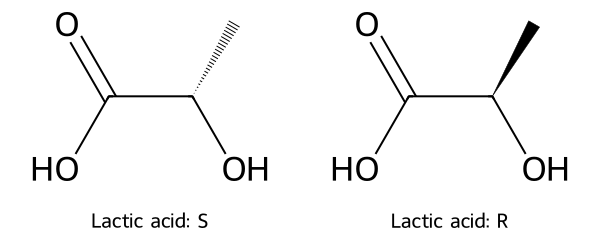

In [12]:
stereo_smiles = ['C[C@H](O)C(=O)O', 'C[C@@H](O)C(=O)O']
stereo_mols = [Chem.MolFromSmiles(s) for s in stereo_smiles]
stereo_labels = [Chem.FindMolChiralCenters(m, includeUnassigned=True)
                 for m in stereo_mols]
display(pd.DataFrame({
    'Input': stereo_smiles, 'Chiral centers (index, label)': stereo_labels,
    'Canonical with stereo': [Chem.MolToSmiles(m) for m in stereo_mols],
    'Without stereo': [Chem.MolToSmiles(m, isomericSmiles=False) for m in stereo_mols],
}))
draw_molecules(stereo_mols, [f'Lactic acid: {centers[0][1]}'
                            for centers in stereo_labels], columns=2)

## SMILES Tokens and One-Hot Encoding

For `CCO` and `COC`, each character is one atom symbol. Use the vocabulary `[C, O]`: C becomes `[1, 0]` and O becomes `[0, 1]`.

Stack the vectors in token order to encode each string.


In [13]:
token_vocab = ['C', 'O']
token_to_index = {token: i for i, token in enumerate(token_vocab)}
token_sequences = {'Ethanol': list('CCO'), 'Dimethyl ether': list('COC')}
display(pd.DataFrame({
    'Token sequence': token_sequences,
}))

one_hot = {}
for name, tokens in token_sequences.items():
    indices = [token_to_index[token] for token in tokens]
    one_hot[name] = np.eye(len(token_vocab), dtype=int)[indices]
    print(name)
    display(pd.DataFrame(one_hot[name], columns=token_vocab,
                         index=[f'{i + 1}: {t}' for i, t in enumerate(tokens)]))

,Token sequence
Ethanol,"[C, C, O]"
Dimethyl ether,"[C, O, C]"


Ethanol


,C,O
1: C,1,0
2: C,1,0
3: O,0,1


Dimethyl ether


,C,O
1: C,1,0
2: O,0,1
3: C,1,0


The rows preserve token order. Summing them gives token counts and loses that order. Ethanol and dimethyl ether both give `[2, 1]`.


In [14]:
token_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, matrix in one_hot.items()
}, index=token_vocab).T
display(token_counts)
print('Same token counts:', token_counts.iloc[0].equals(token_counts.iloc[1]))

,C,O
Ethanol,2,1
Dimethyl ether,2,1


Same token counts: True


Character splitting fails for more complex SMILES. `Cl` is one atom symbol, and `[NH4+]` is one bracketed atom expression. Ring labels and parentheses also have meaning.

Use the parsed RDKit graph to count elements.


In [15]:
text_examples = ['CCCl', '[NH4+]', 'c1ccccc1']
display(pd.DataFrame([{
    'SMILES': s, 'Characters': list(s),
    'Atom elements from RDKit': [a.GetSymbol()
                                for a in Chem.MolFromSmiles(s).GetAtoms()],
} for s in text_examples]))

,SMILES,Characters,Atom elements from RDKit
0,CCCl,"[C, C, C, l]","[C, C, Cl]"
1,[NH4+],"[[, N, H, 4, +, ]]",[N]
2,c1ccccc1,"[c, 1, c, c, c, c, c, 1]","[C, C, C, C, C, C]"


## Atom Counts

Count C and O atoms in the molecular graph, using column order `[C, O]`. Hydrogen atoms are excluded. Aromatic and nonaromatic carbon both count as C.


In [16]:
def atom_counts(mol):
    return Counter(a.GetSymbol() for a in mol.GetAtoms() if a.GetAtomicNum() != 1)

atom_vocab = ['C', 'O']
atom_features = pd.DataFrame([
    [atom_counts(mol)[element] for element in atom_vocab]
    for mol in pair.values()
], index=pair, columns=atom_vocab)
display(atom_features)

,C,O
Ethanol,2,1
Dimethyl ether,2,1


## Bond Counts

Group each bond by its endpoint elements and bond type. A C–O single bond and an O–C single bond belong to the same category. Count each bond once and exclude bonds to hydrogen.

Keep single, double, triple, and aromatic bonds in separate categories.


In [17]:
def bond_key(bond):
    elements = sorted([bond.GetBeginAtom().GetSymbol(),
                       bond.GetEndAtom().GetSymbol()])
    return (elements[0], elements[1], str(bond.GetBondType()))

def bond_counts(mol):
    return Counter(bond_key(b) for b in mol.GetBonds()
                   if b.GetBeginAtom().GetAtomicNum() != 1
                   and b.GetEndAtom().GetAtomicNum() != 1)

bond_vocab = [('C', 'C', 'SINGLE'), ('C', 'O', 'SINGLE')]
bond_features = pd.DataFrame([
    [bond_counts(mol)[key] for key in bond_vocab] for mol in pair.values()
], index=pair, columns=['C-C single', 'C-O single'])
display(bond_features)

,C-C single,C-O single
Ethanol,1,1
Dimethyl ether,0,2


In [18]:
bond_examples = {'Ethane': 'CC', 'Ethene': 'C=C', 'Ethyne': 'C#C',
                 'Benzene': 'c1ccccc1'}
display(pd.DataFrame([{
    'Molecule': name,
    'Bond-category counts': dict(bond_counts(Chem.MolFromSmiles(s))),
} for name, s in bond_examples.items()]).set_index('Molecule'))

,Bond-category counts
Molecule,
Ethane,"{('C', 'C', 'SINGLE'): 1}"
Ethene,"{('C', 'C', 'DOUBLE'): 1}"
Ethyne,"{('C', 'C', 'TRIPLE'): 1}"
Benzene,"{('C', 'C', 'AROMATIC'): 6}"


`GetBonds()` includes branch and ring-closure bonds. Counting adjacent characters in SMILES would miss some of these connections.


## Combining Atom and Bond Counts

Concatenate the atom and bond counts in a fixed column order:

$$\mathbf{x}=[\mathbf{a},\mathbf{b}].$$

Using `[C atoms, O atoms, C–C single bonds, C–O single bonds]`, ethanol gives `[2, 1, 1, 1]` and dimethyl ether gives `[2, 1, 0, 2]`.


In [19]:
combined = pd.concat([
    atom_features.rename(columns={'C': 'C atoms', 'O': 'O atoms'}),
    bond_features,
], axis=1)
display(combined)
print('Ethanol:', combined.loc['Ethanol'].tolist())
print('Dimethyl ether:', combined.loc['Dimethyl ether'].tolist())

,C atoms,O atoms,C-C single,C-O single
Ethanol,2,1,1,1
Dimethyl ether,2,1,0,2


Ethanol: [2, 1, 1, 1]
Dimethyl ether: [2, 1, 0, 2]


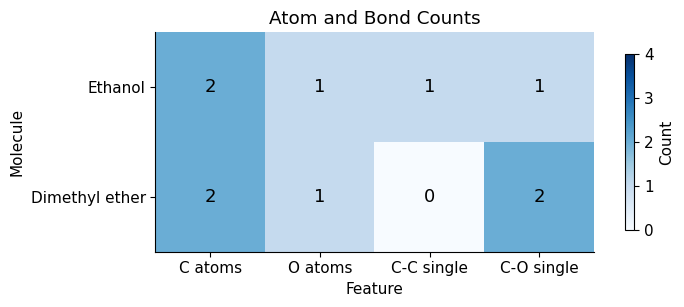

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(combined.to_numpy(), cmap='Blues', vmin=0, vmax=4)
ax.set_xticks(range(combined.shape[1]), combined.columns)
ax.set_yticks(range(len(combined)), combined.index)
for row in range(len(combined)):
    for column in range(combined.shape[1]):
        ax.text(column, row, str(combined.iloc[row, column]),
                ha='center', va='center', color='black', fontsize=13)
ax.set(title='Atom and Bond Counts', xlabel='Feature', ylabel='Molecule')
fig.colorbar(im, ax=ax, label='Count', ticks=range(5), shrink=0.8)
fig.tight_layout()
plt.show()

## Limits of Count Features

1-Propanol and 2-propanol have the same atom and bond counts. Predict their vectors before running the next cell.

Could a model distinguish them using only these vectors?


,C atoms,O atoms,C-C single,C-O single
1-Propanol,3,1,2,1
2-Propanol,3,1,2,1


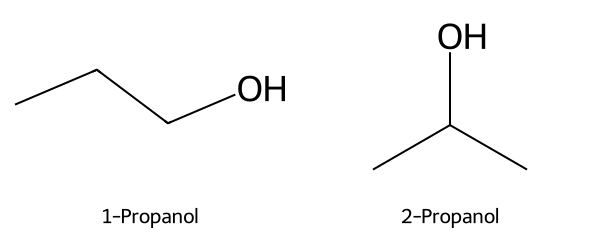

Feature vectors are equal: True


In [21]:
propanol_smiles = {'1-Propanol': 'CCCO', '2-Propanol': 'CC(O)C'}
propanols = {name: Chem.MolFromSmiles(s) for name, s in propanol_smiles.items()}
propanol_features = pd.DataFrame([
    [atom_counts(m)[k] for k in atom_vocab]
    + [bond_counts(m)[k] for k in bond_vocab]
    for m in propanols.values()
], index=propanols, columns=combined.columns)
display(propanol_features)
draw_molecules(propanols.values(), propanols.keys(), columns=2)
print('Feature vectors are equal:',
      propanol_features.iloc[0].equals(propanol_features.iloc[1]))

Both molecules give `[3, 1, 2, 1]`. The counts omit how the bonds connect.

In 1-propanol, the carbon bonded to OH has one carbon neighbor. In 2-propanol, it has two. Molecular fingerprints can encode local environments like these.


In [22]:
local_environments = []
for name, mol in propanols.items():
    oxygen = next(a for a in mol.GetAtoms() if a.GetSymbol() == 'O')
    carbon = next(a for a in oxygen.GetNeighbors() if a.GetSymbol() == 'C')
    local_environments.append({
        'Molecule': name,
        'Carbon neighbors of OH-bearing carbon':
            sum(a.GetSymbol() == 'C' for a in carbon.GetNeighbors()),
        'H on OH-bearing carbon': carbon.GetTotalNumHs(),
    })
display(pd.DataFrame(local_environments).set_index('Molecule'))

,Carbon neighbors of OH-bearing carbon,H on OH-bearing carbon
Molecule,,
1-Propanol,1,2
2-Propanol,2,1
